In [1]:
import pandas as pd

df = pd.read_csv("train.csv")
df.head()
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

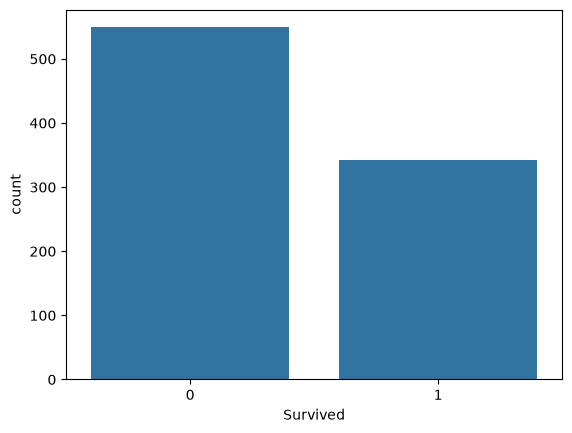

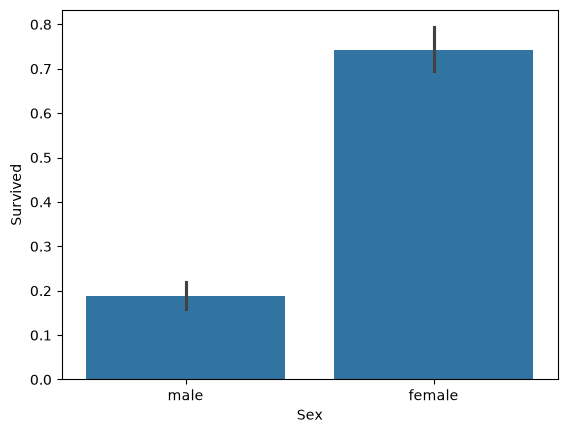

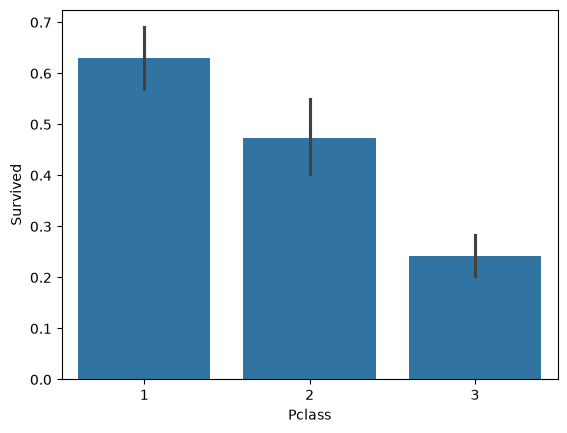

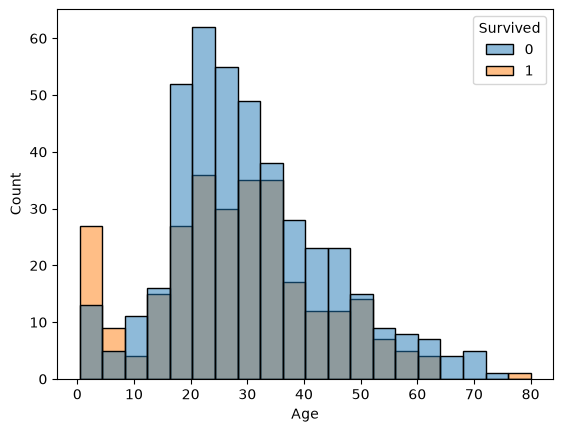

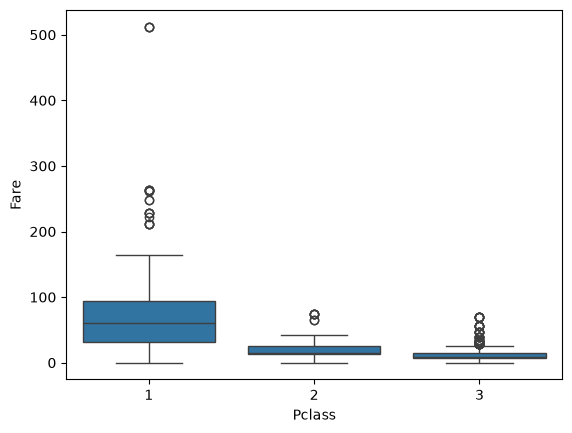

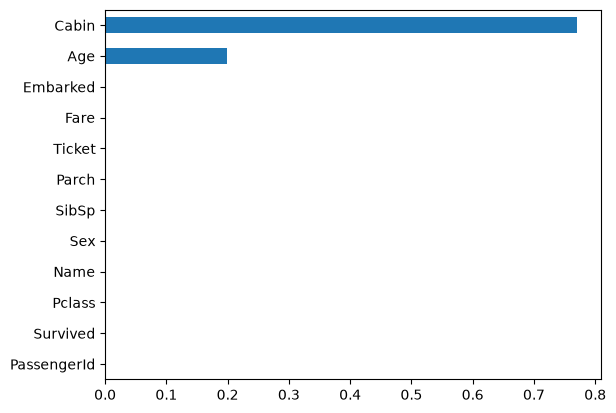

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Survived")
plt.show()

sns.barplot(data=df, x="Sex", y="Survived")
plt.show()

sns.barplot(data=df, x="Pclass", y="Survived")
plt.show()

sns.histplot(data=df, x="Age", hue="Survived", bins=20)
plt.show()

sns.boxplot(data=df, x="Pclass", y="Fare")
plt.show()

df.isna().mean().sort_values().plot.barh()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
y = df["Survived"]

X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].median())
X["Embarked"] = X["Embarked"].fillna(X["Embarked"].mode()[0])
X = pd.get_dummies(X, columns=["Sex", "Embarked"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

models = {
    "Linear": (LogisticRegression(max_iter=1000), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=4, random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42), False),
    "XGBoost": (XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                              random_state=42, eval_metric="logloss"), False),
    "CatBoost": (CatBoostClassifier(iterations=200, depth=4, learning_rate=0.1,
                                    verbose=0, random_state=42), False),
    "KNN": (KNeighborsClassifier(n_neighbors=7), True),
}

rows = []
fitted = {}
for name, (model, scaled) in models.items():
    xt, xe = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    model.fit(xt, y_train)
    pred = model.predict(xe)
    proba = model.predict_proba(xe)[:, 1]
    fitted[name] = model
    rows.append({
        "model": name,
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "f1": round(f1_score(y_test, pred), 3),
        "roc_auc": round(roc_auc_score(y_test, proba), 3),
    })

pd.DataFrame(rows).sort_values("roc_auc", ascending=False)

,model,accuracy,f1,roc_auc
5,KNN,0.821,0.761,0.849
0,Linear,0.804,0.724,0.843
4,CatBoost,0.821,0.750,0.840
2,Random Forest,0.810,0.742,0.835
1,Decision Tree,0.788,0.667,0.821
3,XGBoost,0.799,0.719,0.802


c:\Users\desper61\Desktop\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


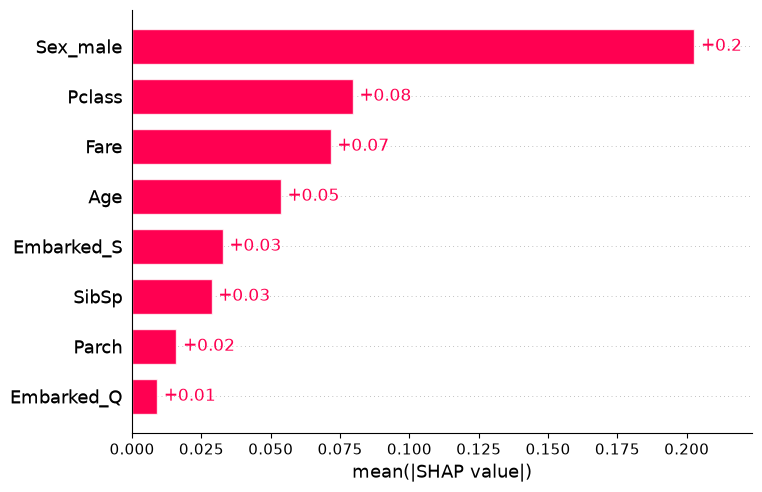

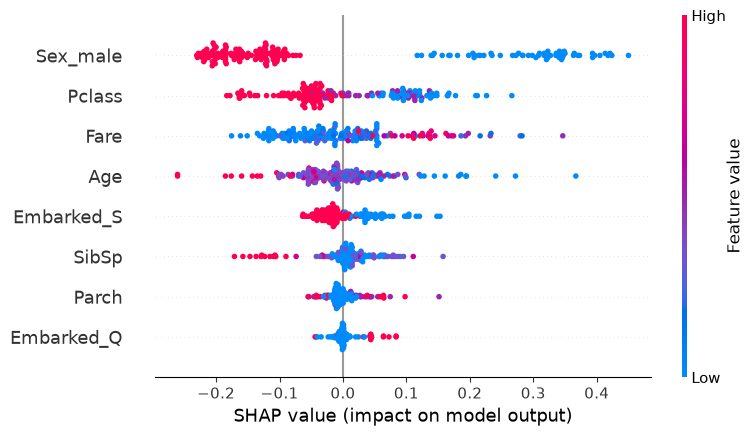

In [8]:
import shap

forest = fitted["Random Forest"]
explainer = shap.TreeExplainer(forest)
shap_values = explainer(X_test)

if shap_values.values.ndim == 3:
    shap_values.values = shap_values.values[:, :, 1]

shap.plots.bar(shap_values)
shap.plots.beeswarm(shap_values)